# Action spaces and normalisation, on real robot data

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/3_robot_learning/04_action_spaces.ipynb) &nbsp; Guide note: [guide-robot-learning-basics](https://www.matthewwnuk.com/guide-robot-learning-basics.html#normalise)

What exactly does a policy output? This notebook looks at 379 real demonstrations to show the same
motion written as absolute positions and as relative steps, how a relative action relates to the motion
it produced, why actions must be normalised, and why step-to-step deltas drift.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
d = data.libero(); A, S, EP = d["action"], d["state"], d["episode"]
print("actions", A.shape, " states", S.shape, " episodes", len(np.unique(EP)))
print("state  = hand position (3), hand orientation (3), two gripper fingers (2)")
print("action = change in position (3), change in orientation (3), gripper command (1)")

actions (101469, 7)  states (101469, 8)  episodes 379
state  = hand position (3), hand orientation (3), two gripper fingers (2)
action = change in position (3), change in orientation (3), gripper command (1)


## One motion, written two ways

The state records where the hand is: an absolute description. The action records how far to move at each
step: a relative one.

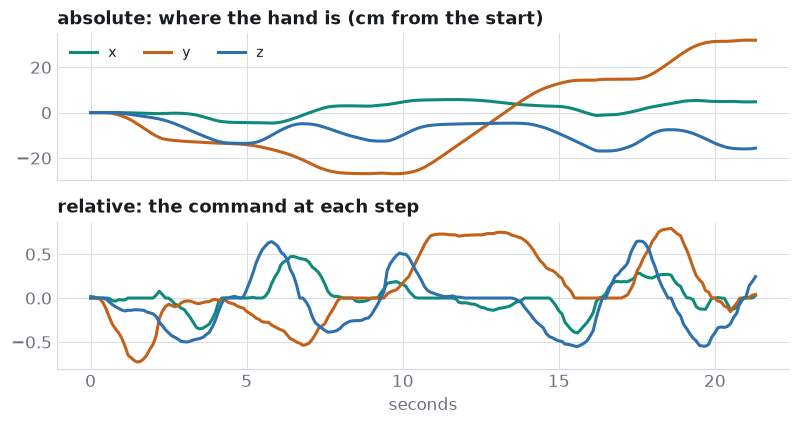

In [3]:
m = EP == 0; s, a = S[m, :3], A[m, :3]; t = np.arange(m.sum()) / 10; fig, ax = plt.subplots(2, 1, figsize=(7.4, 4), sharex=True)
for k, n in enumerate("xyz"): ax[0].plot(t, (s[:, k] - s[0, k]) * 100, label=n); ax[1].plot(t, a[:, k])
ax[0].set_title("absolute: where the hand is (cm from the start)"); ax[0].legend(ncol=3, fontsize=9); ax[1].set_title("relative: the command at each step"); ax[1].set_xlabel("seconds"); plt.tight_layout(); plt.show()

## What does a relative action of 1.0 mean?

Compare each commanded step with the motion that followed it, across every episode.

x: a command of 1.0 moves the hand 1.08 cm in one step   (correlation 0.93)
y: a command of 1.0 moves the hand 1.21 cm in one step   (correlation 0.97)
z: a command of 1.0 moves the hand 1.16 cm in one step   (correlation 0.96)


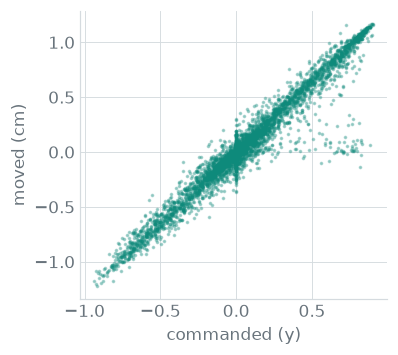

In [4]:
same = EP[1:] == EP[:-1]; moved = (S[1:, :3] - S[:-1, :3])[same] * 100; cmd = A[:-1, :3][same]
for k, n in enumerate("xyz"):
    scale = (cmd[:, k] @ moved[:, k]) / (cmd[:, k] @ cmd[:, k]); print(f"{n}: a command of 1.0 moves the hand {scale:.2f} cm in one step   (correlation {np.corrcoef(cmd[:, k], moved[:, k])[0, 1]:.2f})")
i = np.random.default_rng(0).choice(len(cmd), 5000, replace=False); plt.figure(figsize=(3.6, 3.4)); plt.scatter(cmd[i, 1], moved[i, 1], s=2, alpha=0.3); plt.xlabel("commanded (y)"); plt.ylabel("moved (cm)"); plt.show()

The action is a scaled velocity command, and the controller follows it closely. A policy never sees this
scale. It is part of the dataset's convention, and a different dataset will use a different one.

## Why actions must be normalised

The seven action values do not share a scale.

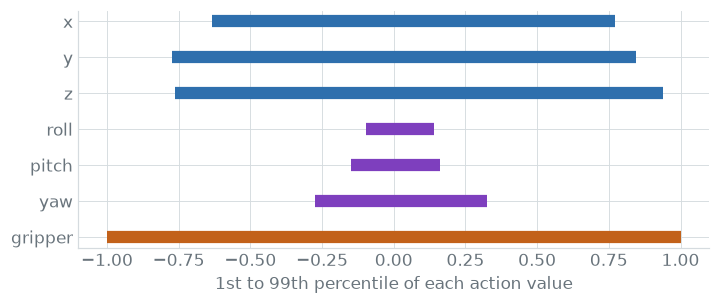

share of a squared-error loss, if every value is predicted equally well in relative terms:
  position 25.5%   rotation 0.9%   gripper 73.6%


In [5]:
names = ["x", "y", "z", "roll", "pitch", "yaw", "gripper"]; lo, hi = np.percentile(A, 1, 0), np.percentile(A, 99, 0)
plt.figure(figsize=(7.4, 2.8))
for i, n in enumerate(names): plt.plot([lo[i], hi[i]], [6 - i, 6 - i], lw=8, solid_capstyle="butt", color=(style.BLUE if i < 3 else style.PURPLE if i < 6 else style.ORANGE))
plt.yticks(range(7), names[::-1]); plt.xlabel("1st to 99th percentile of each action value"); plt.show()
var = A.var(0); share = np.array([var[:3].sum(), var[3:6].sum(), var[6]]) / var.sum()
print("share of a squared-error loss, if every value is predicted equally well in relative terms:"); print(f"  position {share[0]:.1%}   rotation {share[1]:.1%}   gripper {share[2]:.1%}")

Trained on the raw values, a model would learn to open and close on time and never learn to turn the
wrist. The fix is to rescale every value with statistics from the training set, and to undo it before
sending actions to the robot.

In [6]:
def normalise(x, lo, hi): return np.clip(2 * (x - lo) / (hi - lo) - 1, -1, 1)
def denormalise(x, lo, hi): return (x + 1) / 2 * (hi - lo) + lo
An = normalise(A, lo, hi); var = An.var(0); share = np.array([var[:3].sum(), var[3:6].sum(), var[6]]) / var.sum()
print(f"after normalising: position {share[0]:.1%}   rotation {share[1]:.1%}   gripper {share[2]:.1%}")
print("round trip error:", np.abs(denormalise(normalise(A, lo, hi), lo, hi) - np.clip(A, lo, hi)).max())
wrong_lo, wrong_hi = lo * 1.5, hi * 1.5; print(f"decoding with another dataset's statistics changes the commands by {np.abs(denormalise(An, wrong_lo, wrong_hi) - denormalise(An, lo, hi)).mean() / np.abs(A).mean():.0%} on average")

after normalising: position 29.5%   rotation 15.7%   gripper 54.8%
round trip error: 8.940697e-08
decoding with another dataset's statistics changes the commands by 50% on average


The gripper keeps the largest share per value even after normalising, because it is a switch that sits
at its two extremes. Many policies handle it separately for that reason.

## What is a delta relative to?

Suppose every predicted action carries a small error. If each action is relative to the previous step,
the errors add up without limit. If each action in a chunk is relative to the pose at the start of the
chunk, the error resets whenever a new chunk begins.

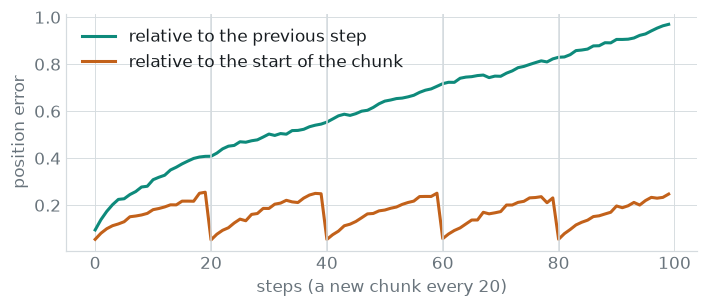

In [7]:
rng = np.random.default_rng(1); n, runs, chunk = 100, 400, 20; err = rng.normal(0, 0.12, (runs, n))
step_wise = np.abs(np.cumsum(err, 1)).mean(0)                                           # every error is carried forward
chunk_wise = np.abs(err * np.sqrt(((np.arange(n) % chunk) + 1) / 3.0)).mean(0)            # error grows within a chunk, then resets
plt.figure(figsize=(7.4, 2.8)); plt.plot(step_wise, label="relative to the previous step"); plt.plot(chunk_wise, label="relative to the start of the chunk")
for k in range(chunk, n, chunk): plt.axvline(k, color=style.LINE, lw=1)
plt.xlabel("steps (a new chunk every 20)"); plt.ylabel("position error"); plt.legend(); plt.show()

## Things to try

- Integrate the recorded actions of one episode with the measured scale and compare with the recorded positions. How far apart are they by the end?
- Normalise with the mean and standard deviation instead of percentiles. What happens to the gripper value?
- Compute the statistics from one task only and apply them to another.